# EMSC 2019 – Parte 1/3: corpo cilíndrico excêntrico rolando sem escorregar

**PME 3200 – Mecânica II (Escola Politécnica da USP)** — Exercício de Modelagem e Simulação Computacional.

**Enunciado (resumo).** Um corpo rígido é formado por um setor recortado de um disco homogêneo (centro $A$, raio $R$, massa $m$),
encaixado em um anel de raio $R$ de espessura e inércia desprezíveis, que **rola sem escorregar** sobre um plano horizontal fixo.
O centro de massa $G$ dista $e$ de $A$ e o ângulo $\theta$ mede a inclinação do segmento $GA$ em relação à vertical.

Este notebook resolve os itens **1.1 a 1.10** combinando:

* **Mecânica newtoniana (teoremas)** – Teorema da Resultante (TR) e Teorema do Momento da Quantidade de Movimento (TMQM);
* **Mecânica analítica** – equações de Lagrange, usadas como verificação independente da equação de movimento;
* `sympy` para todas as deduções literais e `scipy.integrate.solve_ivp` (equivalente, em Python, à função `ode` do Scilab) para a integração numérica.

**Convenções adotadas.** Eixo $x$ horizontal para a direita, $y$ vertical para cima e $\vec k=\vec\imath\times\vec\jmath$ saindo do papel.
O ângulo $\theta$ é tomado **positivo no sentido horário** (como na figura do enunciado: para $\theta>0$ o ponto $G$ fica à esquerda da vertical que passa por $A$),
de modo que o vetor de rotação do corpo é $\vec\omega=-\dot\theta\,\vec k$. Em $\theta=0$ o centro de massa $G$ está diretamente abaixo de $A$.

In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

sp.init_printing(use_latex="mathjax")
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})

## 0. Propriedades geométricas e inerciais do corpo

O corpo é um **setor circular homogêneo** de raio $R$ e ângulo de abertura $\alpha$ (o anel não tem inércia).
Como a distribuição radial de massa de um setor é idêntica à de um disco completo, o momento de inércia em relação ao eixo por $A$ é

$$I_A=\int r^2\,dm=\frac{m}{\alpha R^2/2}\int_0^\alpha\!\!\int_0^R r^3\,dr\,d\varphi=\frac12 mR^2 ,$$

**independentemente de $\alpha$**. A excentricidade do centro de massa é $e=\dfrac{4R\sin(\alpha/2)}{3\alpha}$, que varia de $0$ (disco completo, $\alpha=2\pi$)
até $2R/3$ (setor infinitamente fino, $\alpha\to0$). Logo todos os valores de $e$ pedidos ($0{,}05R$, $0{,}1R$, $0{,}2R$, $0{,}5R$) são fisicamente realizáveis.
Pelo teorema de Steiner, o momento de inércia baricêntrico é

$$I_G=I_A-me^2=m\left(\frac{R^2}{2}-e^2\right).$$

In [2]:
m, R, e, g = sp.symbols("m R e g", positive=True)
alpha, r, phi = sp.symbols("alpha r varphi", positive=True)

# densidade superficial do setor e momento de inércia em relação a A (eixo perpendicular ao plano)
sigma = m / (alpha * R**2 / 2)
I_A = sp.simplify(sp.integrate(sigma * r**2 * r, (r, 0, R), (phi, 0, alpha)))

# posição do centro de massa (distância ao centro A), setor simétrico em relação ao eixo varphi = 0
e_alpha = sp.simplify(sp.integrate(sigma * r * sp.cos(phi) * r, (r, 0, R), (phi, -alpha/2, alpha/2)) / m)

I_G = sp.simplify(I_A - m * e**2)
print("I_A ="); display(I_A)
print("e(alpha) ="); display(e_alpha)
print("I_G ="); display(I_G)
print("limites de e/R:", sp.limit(e_alpha/R, alpha, 2*sp.pi), "(disco completo) ...", sp.limit(e_alpha/R, alpha, 0), "(setor fino)")

I_A =


 2  
R ⋅m
────
 2  

e(alpha) =


       ⎛α⎞
4⋅R⋅sin⎜─⎟
       ⎝2⎠
──────────
   3⋅α    

I_G =


  ⎛ 2      2⎞
m⋅⎝R  - 2⋅e ⎠
─────────────
      2      

limites de e/R: 0 (disco completo) ... 2/3 (setor fino)


## 1.1 Equação de movimento pelos teoremas da Mecânica

### Cinemática (rolamento sem escorregamento)

Com $\vec\omega=-\dot\theta\,\vec k$ e o ponto de contato $C$ com velocidade nula (vínculo de rolamento),

$$\vec v_A=\vec\omega\times(A-C)=-\dot\theta\,\vec k\times R\,\vec\jmath=R\dot\theta\,\vec\imath\quad\Rightarrow\quad x_A=R\theta,\qquad y_A=R .$$

A posição de $G$ em relação a $A$ (rotação horária de $\theta$ a partir da vertical para baixo) é $G-A=-e\sin\theta\,\vec\imath-e\cos\theta\,\vec\jmath$, logo

$$x_G=R\theta-e\sin\theta,\qquad y_G=R-e\cos\theta .$$

### Forças externas sobre o corpo

* peso $-mg\,\vec\jmath$ aplicado em $G$;
* reação do plano em $C$: componente normal $N\vec\jmath$ e atrito $F\vec\imath$ (incógnitas, pois o vínculo é de rolamento sem escorregamento).

### Teoremas

* **TR**: $m\ddot x_G=F$ e $m\ddot y_G=N-mg$;
* **TMQM com pólo no centro de massa $G$**: $I_G\,\alpha_z=\sum M_{G,z}$, com $\alpha_z=-\ddot\theta$ e
  $\sum M_{G,z}=\big[(C-G)\times(F\vec\imath+N\vec\jmath)\big]_z$.

Eliminando $F$ e $N$ obtém-se a EDO não-linear em $\theta$. O procedimento completo é feito a seguir com `sympy`.

In [3]:
t = sp.symbols("t")
th = sp.Function("theta")(t)
thd, thdd = th.diff(t), th.diff(t, 2)

# cinemática
xA, yA = R*th, R
xG, yG = xA - e*sp.sin(th), yA - e*sp.cos(th)
aGx, aGy = xG.diff(t, 2), yG.diff(t, 2)

# incógnitas de contato
F, N = sp.symbols("F N")

# Teorema da Resultante
TR_x = sp.Eq(m*aGx, F)
TR_y = sp.Eq(m*aGy, N - m*g)

# TMQM com pólo em G (alpha_z = -thdd, pois theta é horário)
rCG = sp.Matrix([xA - xG, 0 - yG])           # vetor (C - G)
M_Gz = rCG[0]*N - rCG[1]*F                     # componente z de (C-G) x (F, N)
TMQM_G = sp.Eq(I_G*(-thdd), M_Gz)

# elimina F e N
sol_FN = sp.solve([TR_x, TR_y], [F, N])
eom_newton = sp.expand((TMQM_G.lhs - TMQM_G.rhs).subs(sol_FN))
eom_newton = sp.collect(eom_newton, [thdd, thd**2])
# normaliza: divide por -m para ficar na forma (...)thdd + (...)thd^2 + (...) = 0
eom_newton = sp.simplify(-eom_newton/m)
eom_newton = sp.collect(sp.expand(eom_newton), [thdd, thd**2])
print("Equação de movimento (TR + TMQM), dividida por m:")
display(sp.Eq(eom_newton, 0))

# forças de contato em função do movimento (úteis mais adiante)
F_expr = sp.simplify(sol_FN[F]); N_expr = sp.simplify(sol_FN[N])
print("F (atrito) ="); display(F_expr)
print("N (normal) ="); display(N_expr)

Equação de movimento (TR + TMQM), dividida por m:


                        2                   ⎛   2                  ⎞  2        ↪
              ⎛d       ⎞                    ⎜3⋅R                   ⎟ d         ↪
R⋅e⋅sin(θ(t))⋅⎜──(θ(t))⎟  + e⋅g⋅sin(θ(t)) + ⎜──── - 2⋅R⋅e⋅cos(θ(t))⎟⋅───(θ(t)) ↪
              ⎝dt      ⎠                    ⎝ 2                    ⎠   2       ↪
                                                                     dt        ↪

↪     
↪     
↪  = 0
↪     
↪     

F (atrito) =


  ⎛   2                                2                2       ⎞
  ⎜  d                       ⎛d       ⎞                d        ⎟
m⋅⎜R⋅───(θ(t)) + e⋅sin(θ(t))⋅⎜──(θ(t))⎟  - e⋅cos(θ(t))⋅───(θ(t))⎟
  ⎜    2                     ⎝dt      ⎠                  2      ⎟
  ⎝  dt                                                dt       ⎠

N (normal) =


  ⎛             2                                2    ⎞
  ⎜            d                       ⎛d       ⎞     ⎟
m⋅⎜e⋅sin(θ(t))⋅───(θ(t)) + e⋅cos(θ(t))⋅⎜──(θ(t))⎟  + g⎟
  ⎜              2                     ⎝dt      ⎠     ⎟
  ⎝            dt                                     ⎠

Resultado (dividindo por $m$ e multiplicando por 2):

$$\boxed{\;\left(3R^2-4Re\cos\theta\right)\ddot\theta+2Re\,\dot\theta^2\sin\theta+2ge\sin\theta=0\;}$$

O coeficiente de $\ddot\theta$ é $2I_C/m$, onde $I_C=I_G+m\,|G-C|^2=m\left(\tfrac32R^2-2Re\cos\theta\right)$ é o momento de inércia em relação
ao ponto de contato (centro instantâneo de rotação); o termo em $\dot\theta^2$ aparece porque $I_C$ varia com $\theta$,
e o termo em $g$ é o momento restaurador do peso.

### Verificação pela Mecânica Analítica (Lagrange)

O sistema tem um grau de liberdade ($\theta$), o vínculo de rolamento é holônomo ($x_A=R\theta$) e as forças de vínculo não realizam trabalho
($C$ tem velocidade nula), logo a equação de Lagrange $\dfrac{d}{dt}\dfrac{\partial L}{\partial\dot\theta}-\dfrac{\partial L}{\partial\theta}=0$,
com $L=T-V$, deve reproduzir o resultado acima.

In [4]:
T_cin = sp.Rational(1, 2)*m*(xG.diff(t)**2 + yG.diff(t)**2) + sp.Rational(1, 2)*I_G*thd**2
V_pot = m*g*yG
L = T_cin - V_pot
eom_lagrange = sp.simplify(L.diff(thd).diff(t) - L.diff(th))
eom_lagrange = sp.collect(sp.expand(eom_lagrange/m), [thdd, thd**2])
print("Energia cinética T ="); display(sp.simplify(T_cin))
print("Energia potencial V ="); display(V_pot)
print("Equação de Lagrange (dividida por m):"); display(sp.Eq(eom_lagrange, 0))
print("Diferença entre as duas deduções:", sp.simplify(eom_lagrange - eom_newton))

Energia cinética T =


                                    2
                          ⎛d       ⎞ 
R⋅m⋅(3⋅R - 4⋅e⋅cos(θ(t)))⋅⎜──(θ(t))⎟ 
                          ⎝dt      ⎠ 
─────────────────────────────────────
                  4                  

Energia potencial V =


g⋅m⋅(R - e⋅cos(θ(t)))

Equação de Lagrange (dividida por m):


                        2                   ⎛   2                  ⎞  2        ↪
              ⎛d       ⎞                    ⎜3⋅R                   ⎟ d         ↪
R⋅e⋅sin(θ(t))⋅⎜──(θ(t))⎟  + e⋅g⋅sin(θ(t)) + ⎜──── - 2⋅R⋅e⋅cos(θ(t))⎟⋅───(θ(t)) ↪
              ⎝dt      ⎠                    ⎝ 2                    ⎠   2       ↪
                                                                     dt        ↪

↪     
↪     
↪  = 0
↪     
↪     

Diferença entre as duas deduções: 0


In [5]:
# forma explícita  thdd = f(theta, thd)
thdd_expr = sp.solve(sp.Eq(eom_newton, 0), thdd)[0]
thdd_expr = sp.simplify(thdd_expr)
print("theta'' ="); display(thdd_expr)

theta'' =


    ⎛            2    ⎞          
    ⎜  ⎛d       ⎞     ⎟          
2⋅e⋅⎜R⋅⎜──(θ(t))⎟  + g⎟⋅sin(θ(t))
    ⎝  ⎝dt      ⎠     ⎠          
─────────────────────────────────
    R⋅(-3⋅R + 4⋅e⋅cos(θ(t)))     

## 1.2 Posições de equilíbrio e estabilidade

Em equilíbrio $\dot\theta=\ddot\theta=0$, e a equação se reduz a $2ge\sin\theta=0\Rightarrow\sin\theta=0$:

* $\theta_{eq}=0$ — centro de massa **abaixo** de $A$;
* $\theta_{eq}=\pi$ — centro de massa **acima** de $A$.

**Análise física.** Como as forças de contato não realizam trabalho, o sistema é conservativo e a energia potencial é
$V(\theta)=mg\,y_G=mg(R-e\cos\theta)$. Pelo critério de Lagrange–Dirichlet, o equilíbrio é estável onde $V$ tem mínimo:

* $V''(0)=mge>0$ → **mínimo** → $\theta=0$ é **estável**: qualquer desvio desloca $G$ para fora da vertical por $C$ e o peso gera um momento restaurador em relação ao ponto de contato;
* $V''(\pi)=-mge<0$ → **máximo** → $\theta=\pi$ é **instável**: o momento do peso em relação a $C$ afasta ainda mais o corpo da configuração ("pêndulo invertido" rolante).

Pontos críticos de V(theta): [0, pi]
V''(0) = e*g*m  -> MÍNIMO (estável)
V''(pi) = -e*g*m  -> MÁXIMO (instável)


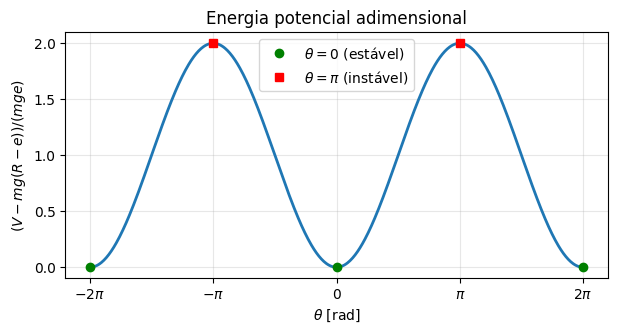

In [6]:
V_theta = V_pot
eq_pts = sp.solve(sp.Eq(V_theta.diff(th), 0), th)
print("Pontos críticos de V(theta):", eq_pts)
for pt in [0, sp.pi]:
    curv = V_theta.diff(th, 2).subs(th, pt)
    print(f"V''({pt}) = {curv}  ->", "MÍNIMO (estável)" if curv > 0 else "MÁXIMO (instável)")

th_num = np.linspace(-2*np.pi, 2*np.pi, 600)
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(th_num, 1 - np.cos(th_num), lw=2)
ax.plot([0, -2*np.pi, 2*np.pi], [0, 0, 0], "go", label=r"$\theta=0$ (estável)")
ax.plot([np.pi, -np.pi], [2, 2], "rs", label=r"$\theta=\pi$ (instável)")
ax.set_xlabel(r"$\theta$ [rad]"); ax.set_ylabel(r"$(V - mg(R-e))/(mge)$")
ax.set_title("Energia potencial adimensional")
ax.set_xticks(np.pi*np.arange(-2, 3)); ax.set_xticklabels([r"$-2\pi$", r"$-\pi$", "0", r"$\pi$", r"$2\pi$"])
ax.legend(); plt.show()

## 1.3 Linearização em torno de cada equilíbrio

Escrevendo a equação como $f(\theta,\dot\theta,\ddot\theta)=0$ e expandindo em série de Taylor de primeira ordem em torno de
$(\theta_{eq},0,0)$:

$$\left.\frac{\partial f}{\partial\ddot\theta}\right|_{eq}\ddot\varphi+\left.\frac{\partial f}{\partial\dot\theta}\right|_{eq}\dot\varphi+\left.\frac{\partial f}{\partial\theta}\right|_{eq}\varphi=0,\qquad \varphi=\theta-\theta_{eq}.$$

O termo em $\dot\theta^2\sin\theta$ é de segunda ordem e desaparece.

In [7]:
TH, W, A = sp.symbols("vartheta omega a")   # símbolos "congelados" para theta, theta', theta''
f_sym = eom_newton.subs({thdd: A, thd: W, th: TH})

def linearizar(theta_eq):
    subs_eq = {TH: theta_eq, W: 0, A: 0}
    c2 = sp.simplify(f_sym.diff(A).subs(subs_eq))
    c1 = sp.simplify(f_sym.diff(W).subs(subs_eq))
    c0 = sp.simplify(f_sym.diff(TH).subs(subs_eq))
    return c2, c1, c0

phi = sp.Function("varphi")(t)
for theta_eq in [0, sp.pi]:
    c2, c1, c0 = linearizar(theta_eq)
    print(f"Linearização em torno de theta = {theta_eq}:")
    display(sp.Eq(sp.expand(2*c2)*phi.diff(t, 2) + sp.expand(2*c1)*phi.diff(t) + sp.expand(2*c0)*phi, 0))

Linearização em torno de theta = 0:


                                  2                
                  ⎛   2        ⎞ d                 
2⋅e⋅g⋅varphi(t) + ⎝3⋅R  - 4⋅R⋅e⎠⋅───(varphi(t)) = 0
                                   2               
                                 dt                

Linearização em torno de theta = pi:


                                   2                
                   ⎛   2        ⎞ d                 
-2⋅e⋅g⋅varphi(t) + ⎝3⋅R  + 4⋅R⋅e⎠⋅───(varphi(t)) = 0
                                    2               
                                  dt                

Resultados:

* Em torno de $\theta=0$:
  $$R(3R-4e)\,\ddot\varphi+2ge\,\varphi=0 .$$
  Como $e<2R/3<3R/4$, o coeficiente de $\ddot\varphi$ é positivo e a "rigidez" $2ge>0$: oscilador harmônico, confirmando a **estabilidade**
  (solução $\varphi=\varphi_0\cos\omega_nt+\dot\varphi_0\sin(\omega_nt)/\omega_n$, limitada).

* Em torno de $\theta=\pi$ ($\varphi=\theta-\pi$):
  $$R(3R+4e)\,\ddot\varphi-2ge\,\varphi=0 .$$
  A "rigidez" é **negativa**: as soluções são $\varphi=C_1e^{\lambda t}+C_2e^{-\lambda t}$ com $\lambda=\sqrt{2ge/(R(3R+4e))}$;
  uma perturbação arbitrariamente pequena cresce exponencialmente — **instabilidade** (ponto de sela no espaço de fase), em concordância com o item 1.2.
  Note que a "inércia efetiva" $R(3R+4e)$ é maior que em $\theta=0$ porque $G$ está mais longe do ponto de contato.

## 1.4 Frequência natural e comprimento equivalente

Da equação linearizada em torno de $\theta=0$:

$$\omega_n=\sqrt{\frac{2ge}{R(3R-4e)}} .$$

Comparando com o pêndulo simples, $\ddot\varphi+(g/\ell)\varphi=0$, define-se o **comprimento equivalente**

$$\ell_{eq}=\frac{g}{\omega_n^2}=\frac{R(3R-4e)}{2e}.$$

Interpretação: o corpo oscila como um pêndulo cuja massa está a $\ell_{eq}$ do pivô. Para $e\ll R$, $\ell_{eq}\approx 3R^2/(2e)\gg R$:
a inércia que resiste ao movimento (translação + rotação, $I_C\approx\tfrac32mR^2$) é grande em relação ao braço $e$ do momento restaurador do peso,
resultando em oscilações lentas. O limite $e\to0$ (disco completo) dá $\omega_n\to0$: o disco homogêneo fica em equilíbrio indiferente.

In [8]:
c2, c1, c0 = linearizar(0)
omega_n_sym = sp.sqrt(sp.simplify(c0/c2))
l_eq_sym = sp.simplify(g/omega_n_sym**2)
print("omega_n ="); display(omega_n_sym)
print("l_eq ="); display(l_eq_sym)

g_num, R_num = 9.8, 0.30
omega_n_f = sp.lambdify((e, R, g), omega_n_sym, "numpy")
l_eq_f = sp.lambdify((e, R, g), l_eq_sym, "numpy")
print("\n  e/R    omega_n [rad/s]   T_n [s]   l_eq [m]   l_eq/R")
for er in [0.05, 0.10, 0.20, 0.50]:
    wn = omega_n_f(er*R_num, R_num, g_num)
    print(f"  {er:4.2f}   {wn:10.4f}      {2*np.pi/wn:6.3f}   {l_eq_f(er*R_num, R_num, g_num):7.4f}   {l_eq_f(er*R_num, R_num, g_num)/R_num:6.2f}")

omega_n =


             ___________
            ╱     1     
√2⋅√e⋅√g⋅  ╱  ───────── 
         ╲╱   3⋅R - 4⋅e 
────────────────────────
           √R           

l_eq =


R⋅(3⋅R - 4⋅e)
─────────────
     2⋅e     


  e/R    omega_n [rad/s]   T_n [s]   l_eq [m]   l_eq/R
  0.05       1.0801       5.817    8.4000    28.00
  0.10       1.5852       3.964    3.9000    13.00
  0.20       2.4371       2.578    1.6500     5.50
  0.50       5.7155       1.099    0.3000     1.00


## 1.5 Forma de espaço de estados

Com o vetor de estados $\mathbf y=\begin{bmatrix}y_1\\y_2\end{bmatrix}=\begin{bmatrix}\theta\\\dot\theta\end{bmatrix}$, a EDO de segunda ordem
torna-se o sistema de primeira ordem $\dot{\mathbf y}=\mathbf f(t,\mathbf y)$:

$$\dot y_1=y_2,\qquad
\dot y_2=-\frac{2e\,\sin y_1\,\left(R\,y_2^2+g\right)}{3R^2-4Re\cos y_1}.$$

O sistema é **autônomo** ($\mathbf f$ não depende explicitamente de $t$) e conservativo.

In [9]:
y1, y2 = sp.symbols("y1 y2")
f_estado = sp.Matrix([y2, thdd_expr.subs({thd: y2, th: y1})])
print("f(y) ="); display(f_estado)

f(y) =


⎡          y₂           ⎤
⎢                       ⎥
⎢    ⎛    2    ⎞        ⎥
⎢2⋅e⋅⎝R⋅y₂  + g⎠⋅sin(y₁)⎥
⎢───────────────────────⎥
⎣R⋅(-3⋅R + 4⋅e⋅cos(y₁)) ⎦

## 1.6 Rotina de integração numérica

O enunciado pede uma rotina Scilab com a função `ode`. Abaixo está a versão Python equivalente, usando `scipy.integrate.solve_ivp`
(método Runge–Kutta de ordem 5(4) de Dormand–Prince, com tolerâncias apertadas — o problema é conservativo e queremos preservar a energia).
Para referência, a rotina Scilab correspondente é:

```scilab
// EMSC 2019 - Parte 1 : integração da equação não-linear em espaço de estados
g = 9.8; R = 0.30; e = 0.20*R;

function dy = f(t, y)
    th = y(1); om = y(2);
    dy(1) = om;
    dy(2) = -2*e*sin(th)*(R*om^2 + g) / (3*R^2 - 4*R*e*cos(th));
endfunction

t  = 0:0.01:20;
y0 = [%pi/6; 0];                 // theta(0), thetaponto(0)
y  = ode(y0, 0, t, f);           // integrador padrão (lsoda)
subplot(3,1,1); plot(t, y(1,:)); xlabel("t [s]"); ylabel("theta [rad]");
subplot(3,1,2); plot(t, y(2,:)); xlabel("t [s]"); ylabel("thetaponto [rad/s]");
subplot(3,1,3); plot(y(1,:), y(2,:)); xlabel("theta"); ylabel("thetaponto");
```

In [10]:
def f_estados(t, y, e, R, g):
    # Campo de velocidades do espaço de estados: y = [theta, theta_ponto]
    th_, om_ = y
    return [om_, -2.0*e*np.sin(th_)*(R*om_**2 + g) / (3.0*R**2 - 4.0*R*e*np.cos(th_))]

def simular(theta0, omega0, e, R=0.30, g=9.8, t_final=20.0, dt=0.005):
    # Integra a equação não-linear de movimento; devolve t, theta(t), theta_ponto(t).
    t_eval = np.arange(0.0, t_final + dt/2, dt)
    sol = solve_ivp(f_estados, (0.0, t_final), [theta0, omega0], t_eval=t_eval,
                    args=(e, R, g), method="DOP853", rtol=1e-10, atol=1e-12)
    return sol.t, sol.y[0], sol.y[1]

def energia_por_massa(th_, om_, e, R=0.30, g=9.8):
    # E/m = T/m + V/m (conservada): útil para checar a qualidade da integração
    return 0.5*(1.5*R**2 - 2*R*e*np.cos(th_))*om_**2 + g*(R - e*np.cos(th_))

# teste rápido: conservação de energia
tt, th_t, om_t = simular(np.pi/6, 0.0, e=0.06)
E = energia_por_massa(th_t, om_t, 0.06)
print(f"Variação relativa máxima da energia na simulação-teste: {np.max(np.abs(E - E[0]))/E[0]:.2e}")

Variação relativa máxima da energia na simulação-teste: 7.14e-12

## 1.7 Simulação dos cenários propostos

Parâmetros fixos: $g=9{,}8\ \mathrm{m/s^2}$, $R=0{,}30\ \mathrm m$. Para cada cenário são apresentados:
(a) $\theta(t)$, (b) $\dot\theta(t)$ e (c) a trajetória no espaço de fase $\dot\theta\times\theta$.
Nas séries temporais também é sobreposta (tracejado) a solução da **equação linearizada** em torno do equilíbrio mais próximo
da condição inicial, para apoiar a discussão do item 1.8. O tempo de simulação foi escolhido para cobrir várias oscilações
(maior nos cenários próximos da separatriz, de período longo).

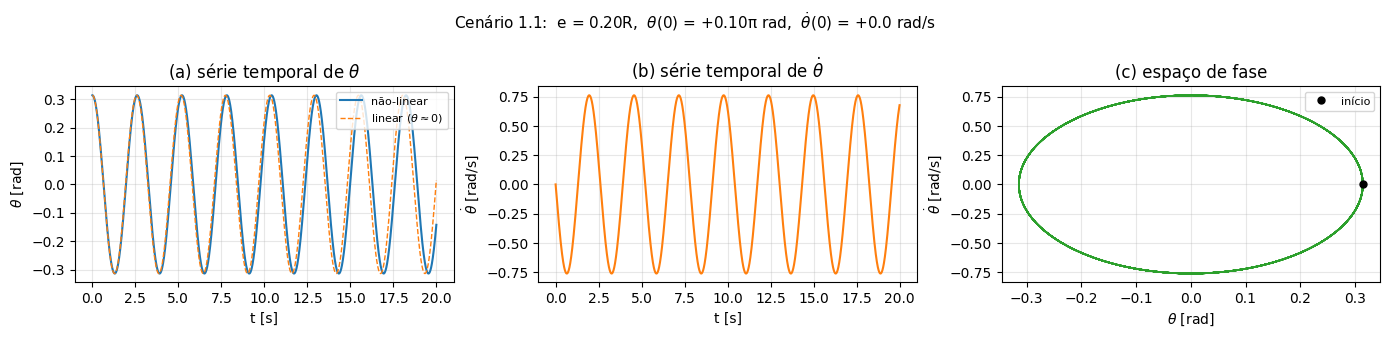

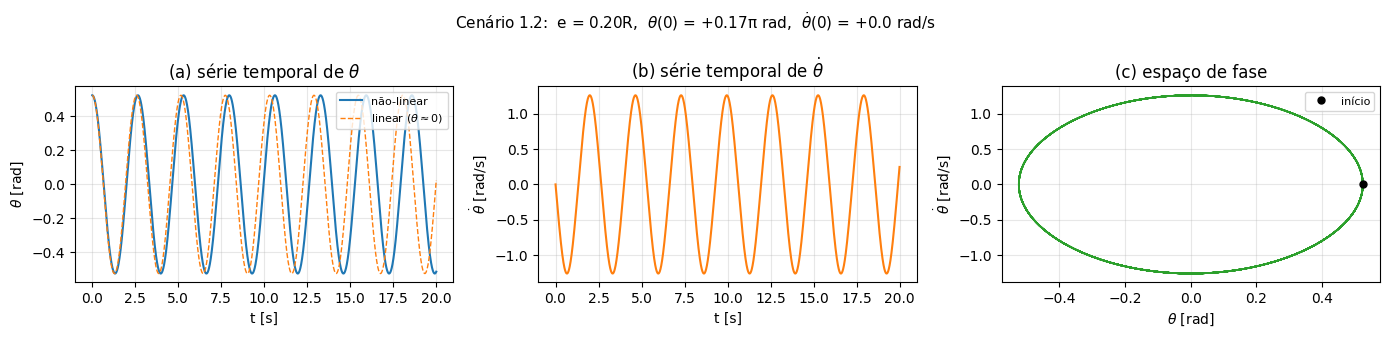

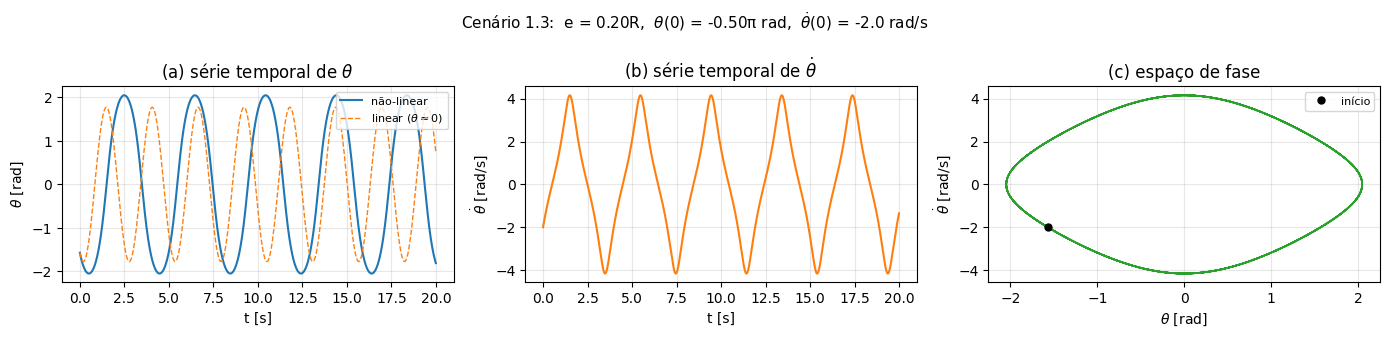

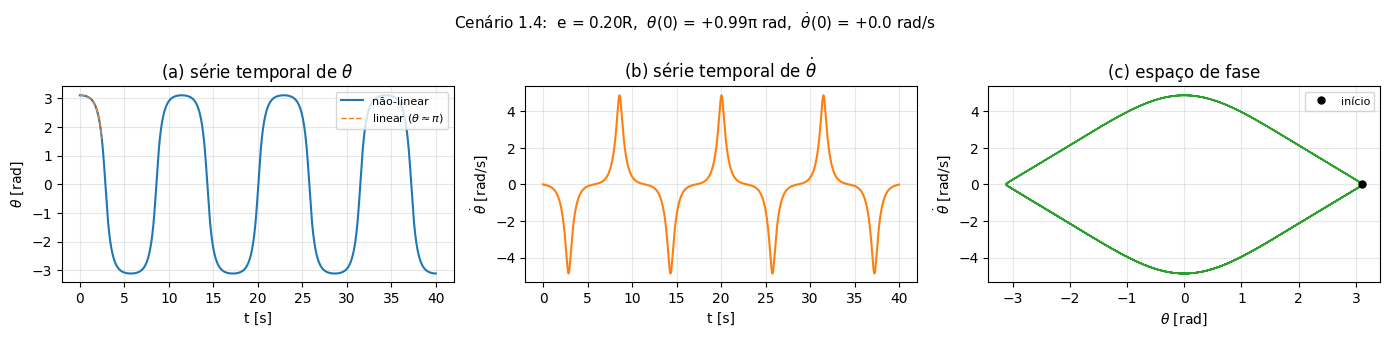

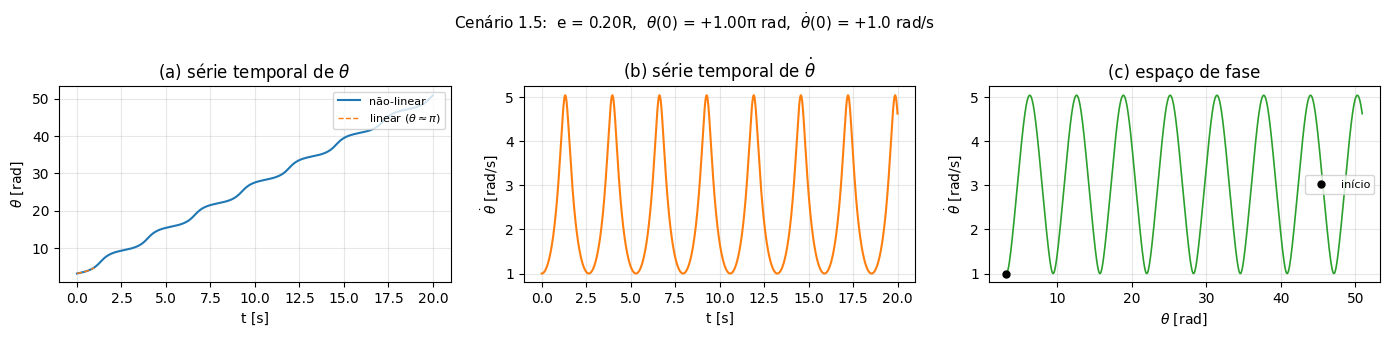

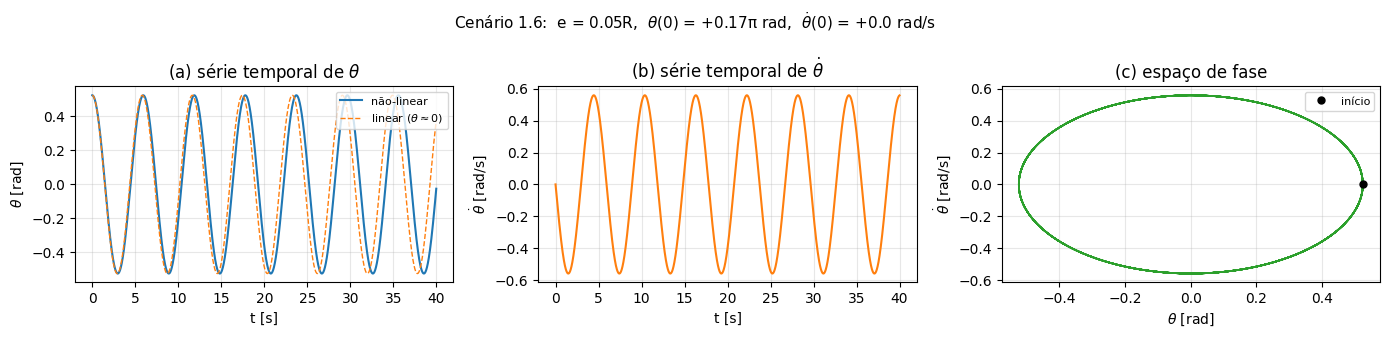

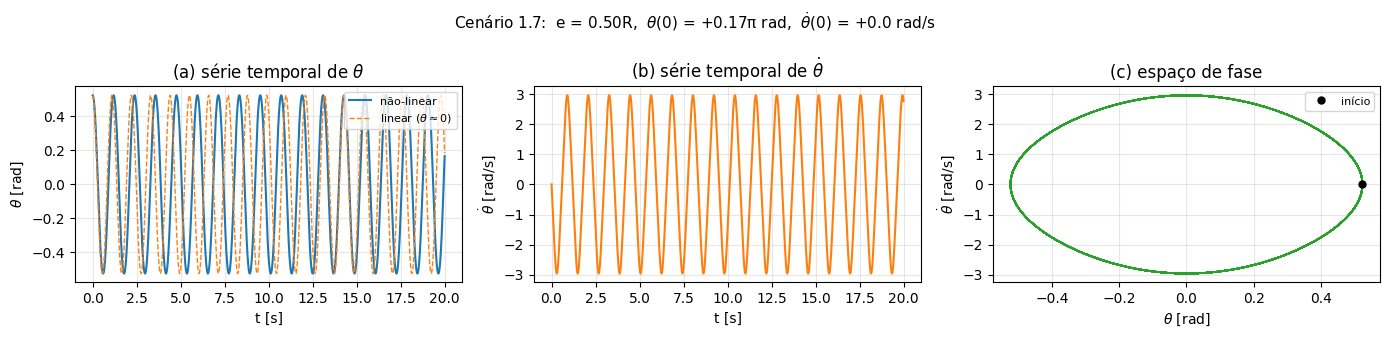

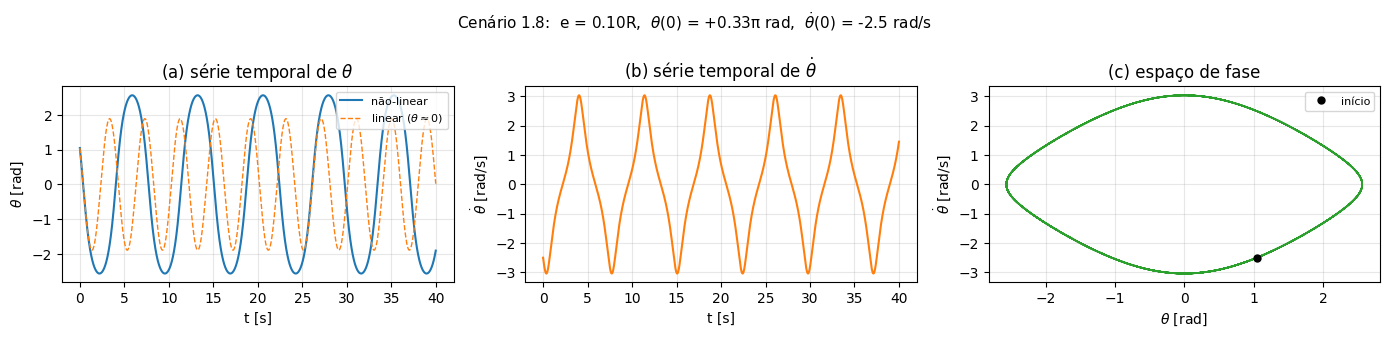

In [11]:
cenarios = {
    "1.1": dict(e=0.20, th0=np.pi/10, om0=0.0,  tf=20.0),
    "1.2": dict(e=0.20, th0=np.pi/6,  om0=0.0,  tf=20.0),
    "1.3": dict(e=0.20, th0=-np.pi/2, om0=-2.0, tf=20.0),
    "1.4": dict(e=0.20, th0=0.99*np.pi, om0=0.0, tf=40.0),
    "1.5": dict(e=0.20, th0=np.pi,    om0=1.0,  tf=20.0),
    "1.6": dict(e=0.05, th0=np.pi/6,  om0=0.0,  tf=40.0),
    "1.7": dict(e=0.50, th0=np.pi/6,  om0=0.0,  tf=20.0),
    "1.8": dict(e=0.10, th0=np.pi/3,  om0=-2.5, tf=40.0),
}

def solucao_linear(t, th0, om0, e, R=0.30, g=9.8):
    # Solução analítica da equação linearizada em torno do equilíbrio mais próximo de th0.
    if np.cos(th0) >= 0:                                    # perto de theta = 0 -> oscilador harmônico
        wn = np.sqrt(2*g*e/(R*(3*R - 4*e)))
        return th0*np.cos(wn*t) + om0/wn*np.sin(wn*t), r"linear ($\theta\approx0$)"
    else:                                                   # perto de theta = pi -> sela (cosh/sinh)
        lam = np.sqrt(2*g*e/(R*(3*R + 4*e)))
        ph = (th0 - np.pi)*np.cosh(lam*t) + om0/lam*np.sinh(lam*t)
        ph[np.abs(ph) > np.pi/2] = np.nan                   # só faz sentido enquanto o desvio é pequeno
        return np.pi + ph, r"linear ($\theta\approx\pi$)"

resultados = {}
for nome, c in cenarios.items():
    e_num = c["e"]*R_num
    t_, th_, om_ = simular(c["th0"], c["om0"], e_num, t_final=c["tf"])
    resultados[nome] = (t_, th_, om_)
    th_lin, rotulo = solucao_linear(t_, c["th0"], c["om0"], e_num)

    fig, axs = plt.subplots(1, 3, figsize=(14, 3.4))
    fig.suptitle(rf"Cenário {nome}:  e = {c['e']:.2f}R,  $\theta(0)$ = {c['th0']/np.pi:+.2f}π rad,  $\dot\theta(0)$ = {c['om0']:+.1f} rad/s", fontsize=11)
    axs[0].plot(t_, th_, lw=1.5, label="não-linear")
    axs[0].plot(t_, th_lin, "--", lw=1, label=rotulo)
    axs[0].set_xlabel("t [s]"); axs[0].set_ylabel(r"$\theta$ [rad]"); axs[0].set_title(r"(a) série temporal de $\theta$")
    axs[0].legend(fontsize=8, loc="upper right")
    axs[1].plot(t_, om_, lw=1.5, color="C1")
    axs[1].set_xlabel("t [s]"); axs[1].set_ylabel(r"$\dot\theta$ [rad/s]"); axs[1].set_title(r"(b) série temporal de $\dot\theta$")
    axs[2].plot(th_, om_, lw=1.2, color="C2"); axs[2].plot(th_[0], om_[0], "ko", ms=5, label="início")
    axs[2].set_xlabel(r"$\theta$ [rad]"); axs[2].set_ylabel(r"$\dot\theta$ [rad/s]"); axs[2].set_title("(c) espaço de fase")
    axs[2].legend(fontsize=8)
    plt.tight_layout(); plt.show()

## 1.8 Validade das formas linearizadas

Para quantificar a comparação visual acima, calcula-se para cada cenário:

* o **período** da resposta não-linear (medido pelos cruzamentos de $\theta$ pelo equilíbrio) em relação a $T_n=2\pi/\omega_n$ da equação linearizada;
* o erro máximo $\max|\theta_{nl}-\theta_{lin}|$ ao longo do primeiro período linear, normalizado pela amplitude;
* a energia total em relação à energia da separatriz $E_{sep}=mg(R+e)$ (energia da posição invertida em repouso), que separa oscilações (libração) de rotações completas.

In [12]:
def periodo_numerico(t, th, th_eq=0.0):
    # Período médio a partir dos cruzamentos ascendentes de theta pelo equilíbrio (libração).
    s = th - th_eq
    idx = np.where((s[:-1] < 0) & (s[1:] >= 0))[0]
    if len(idx) < 2:
        return np.nan
    tc = t[idx] - s[idx]*(t[idx+1]-t[idx])/(s[idx+1]-s[idx])   # interpolação linear do cruzamento
    return np.mean(np.diff(tc))

print(" Cenário   e/R   E/E_sep   regime      T_nl [s]   T_lin [s]   T_nl/T_lin   erro máx. (1º período)")
for nome, c in cenarios.items():
    e_num = c["e"]*R_num
    t_, th_, om_ = resultados[nome]
    E = energia_por_massa(th_[0], om_[0], e_num); E_sep = g_num*(R_num + e_num)
    regime = "rotação" if E > E_sep else "libração"
    wn = np.sqrt(2*g_num*e_num/(R_num*(3*R_num - 4*e_num))); T_lin = 2*np.pi/wn
    T_nl = periodo_numerico(t_, th_) if regime == "libração" else np.nan
    th_lin, _ = solucao_linear(t_, c["th0"], c["om0"], e_num)
    mask = (t_ <= T_lin) & np.isfinite(th_lin)
    amp = max(np.max(np.abs(th_[mask] - (0 if np.cos(c["th0"]) >= 0 else np.pi))), 1e-9)
    erro = np.max(np.abs(th_[mask] - th_lin[mask]))/amp
    print(f"   {nome}    {c['e']:.2f}   {E/E_sep:6.3f}   {regime:9s}  {T_nl:8.3f}   {T_lin:8.3f}    {T_nl/T_lin:7.3f}      {erro:8.3f}")

 Cenário   e/R   E/E_sep   regime      T_nl [s]   T_lin [s]   T_nl/T_lin   erro máx. (1º período)
   1.1    0.20    0.675   libração      2.606      2.578      1.011         0.050
   1.2    0.20    0.689   libração      2.655      2.578      1.030         0.140
   1.3    0.20    0.910   libração      3.971      2.578      1.540         1.758
   1.4    0.20    1.000   libração     11.457      2.578      4.444         0.010
   1.5    0.20    1.024   rotação         nan      2.578        nan         0.020
   1.6    0.05    0.911   libração      5.933      5.817      1.020         0.094
   1.7    0.50    0.378   libração      1.191      1.099      1.083         0.387
   1.8    0.10    0.985   libração      7.352      3.964      1.855         1.498


**Discussão.**

* **Cenário 1.1** ($\theta_0=\pi/10=18^\circ$): a resposta é praticamente senoidal, o período difere do linear em cerca de 1 % — a linearização é **excelente**.
* **Cenário 1.2** ($\theta_0=\pi/6=30^\circ$): ainda **boa** (período 3 % maior); nota-se o leve alongamento do período (efeito de "mola amolecedora" de $\sin\theta<\theta$),
  o mesmo que ocorre no pêndulo simples, mas aqui acentuado pela variação da inércia $I_C(\theta)$.
* **Cenário 1.6** ($e=0{,}05R$, $\theta_0=\pi/6$): mesma amplitude de 1.2, porém com $e$ pequeno a variação relativa de $I_C$ com $\theta$ é menor, e o erro cai: a linearização é **boa**.
* **Cenário 1.7** ($e=0{,}5R$, $\theta_0=\pi/6$): a inércia $3R^2-4Re\cos\theta=R^2(3-2\cos\theta)$ varia fortemente, o termo em $\dot\theta^2$ cresce e a forma de onda se afasta
  da senóide: a linearização é apenas **razoável**, com erro de período já visível.
* **Cenário 1.3** ($\theta_0=-\pi/2$, $\dot\theta_0=-2$ rad/s): oscilação de grande amplitude (quase $\pm\pi$), com energia de 91 % da separatriz: período 54 % maior que $T_n$ e
  forma de onda não senoidal — linearização **inadequada**.
* **Cenário 1.8** ($e=0{,}1R$, $\theta_0=\pi/3$, $\dot\theta_0=-2{,}5$ rad/s): energia ligeiramente abaixo de $E_{sep}$; o corpo quase atinge a posição invertida e "demora" perto dela,
  o que alonga enormemente o período (85 % maior que $T_n$) — linearização **inadequada**.
* **Cenário 1.4** ($\theta_0=0{,}99\pi$): partida junto ao equilíbrio instável. A linearização em torno de $\theta=\pi$ descreve bem o **afastamento inicial** (crescimento exponencial,
  tracejado), mas deixa de valer tão logo $|\theta-\pi|$ cresce; a resposta completa é uma libração de amplitude quase $\pi$ e período longo.
* **Cenário 1.5** ($\theta_0=\pi$, $\dot\theta_0=1$ rad/s): a energia excede $E_{sep}$ e o corpo executa **rotações completas** (θ cresce monotonicamente): nenhuma das linearizações se aplica,
  exceto a de $\theta=\pi$ nos instantes iniciais.

Em resumo, as formas linearizadas são boas aproximações **somente para pequenas amplitudes em torno de $\theta=0$** (cenários 1.1, 1.2 e 1.6, com ressalvas para 1.7), e a
linearização em torno de $\theta=\pi$ serve apenas para caracterizar a instabilidade (taxa de crescimento inicial).

## 1.9 Geometria das trajetórias no espaço de fase

Como o sistema é **conservativo**, cada trajetória é uma curva de nível da energia

$$\frac{E}{m}=\frac12\left(\frac32R^2-2Re\cos\theta\right)\dot\theta^2+g(R-e\cos\theta)=\text{const.}$$

* Para $E<E_{sep}=mg(R+e)$ as curvas são **fechadas** em torno do centro $(0,0)$: o movimento é periódico (libração), $\theta$ oscila entre $\pm\theta_{max}$ e o sentido
  da velocidade se inverte. Perto do centro as curvas são elipses (regime linear); conforme a energia cresce elas se deformam, "achatando-se" perto de $\theta=\pm\pi$,
  onde o corpo se move lentamente.
* Para $E>E_{sep}$ as curvas são **abertas** (ondulações que não cruzam $\dot\theta=0$): o corpo realiza rotações completas, $\theta$ cresce sem limite
  (o corpo rola continuamente, com velocidade angular que oscila entre um mínimo em $\theta=\pi$ e um máximo em $\theta=0$). O movimento é periódico em $\dot\theta$,
  mas não em $\theta$ — se o ângulo for tomado módulo $2\pi$ (cilindro de fase), a curva também se fecha.
* A **separatriz** ($E=E_{sep}$) liga os pontos de sela $(\pm\pi,0)$ e divide os dois regimes; sobre ela o período é infinito.
* Não há espirais (trajetórias que se aproximam ou se afastam de um ponto), o que seria sinal de dissipação ou de fornecimento de energia.

Abaixo as trajetórias dos oito cenários (com $e=0{,}2R$ no retrato de fundo) são sobrepostas às curvas de nível da energia e à separatriz.

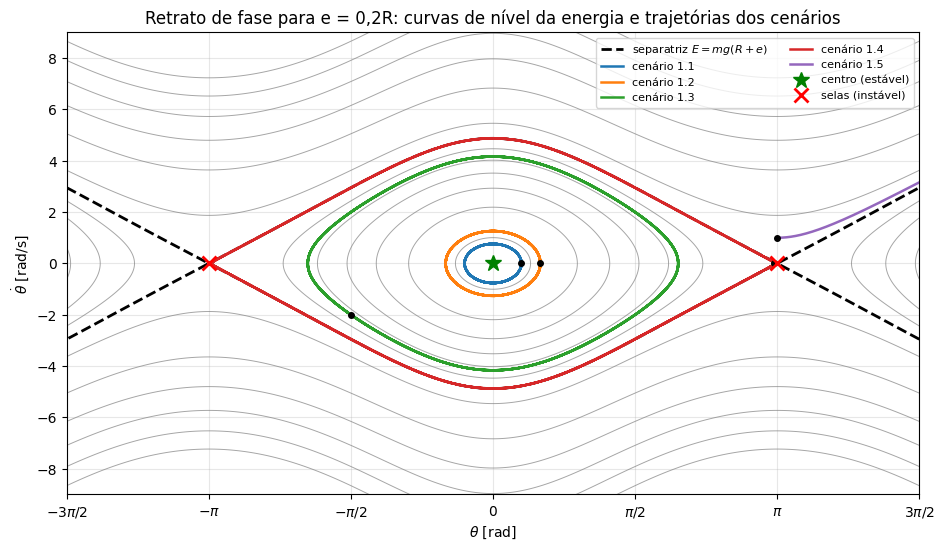

In [13]:
e_num = 0.20*R_num
TH_g, OM_g = np.meshgrid(np.linspace(-1.5*np.pi, 1.5*np.pi, 500), np.linspace(-9, 9, 400))
E_g = energia_por_massa(TH_g, OM_g, e_num)
E_sep = g_num*(R_num + e_num)

fig, ax = plt.subplots(figsize=(11, 6))
niveis = np.sort(np.r_[np.linspace(g_num*(R_num - e_num)+0.05, E_sep, 7)[:-1], np.linspace(E_sep + 0.3, 8, 6)])
ax.contour(TH_g, OM_g, E_g, levels=niveis, colors="gray", linewidths=0.7, alpha=0.7)
ax.contour(TH_g, OM_g, E_g, levels=[E_sep], colors="k", linewidths=2, linestyles="--")
ax.plot([], [], "k--", lw=2, label="separatriz $E=mg(R+e)$")
for nome, c in cenarios.items():
    if c["e"] != 0.20:
        continue
    t_, th_, om_ = resultados[nome]
    ax.plot(th_, om_, lw=1.8, label=f"cenário {nome}")
    ax.plot(th_[0], om_[0], "ko", ms=4)
ax.plot([0], [0], "g*", ms=12, label="centro (estável)"); ax.plot([-np.pi, np.pi], [0, 0], "rx", ms=10, mew=2, label="selas (instável)")
ax.set_xlim(-1.5*np.pi, 1.5*np.pi); ax.set_ylim(-9, 9)
ax.set_xlabel(r"$\theta$ [rad]"); ax.set_ylabel(r"$\dot\theta$ [rad/s]")
ax.set_title("Retrato de fase para e = 0,2R: curvas de nível da energia e trajetórias dos cenários")
ax.set_xticks(np.pi*np.arange(-1.5, 2, 0.5)); ax.set_xticklabels([r"$-3\pi/2$", r"$-\pi$", r"$-\pi/2$", "0", r"$\pi/2$", r"$\pi$", r"$3\pi/2$"])
ax.legend(fontsize=8, loc="upper right", ncol=2); plt.show()

## 1.10 Exploração do modelo

### (a) Período em função da amplitude

O período de libração pode ser obtido exatamente pela integral da energia,
$T=4\displaystyle\int_0^{\theta_{max}}\frac{d\theta}{\dot\theta(\theta)}$ com $\dot\theta=\sqrt{\dfrac{2\,[E/m-g(R-e\cos\theta)]}{\tfrac32R^2-2Re\cos\theta}}$,
e comparado com $T_n$. A curva mostra o quão rápido a linearização se degrada para cada excentricidade.

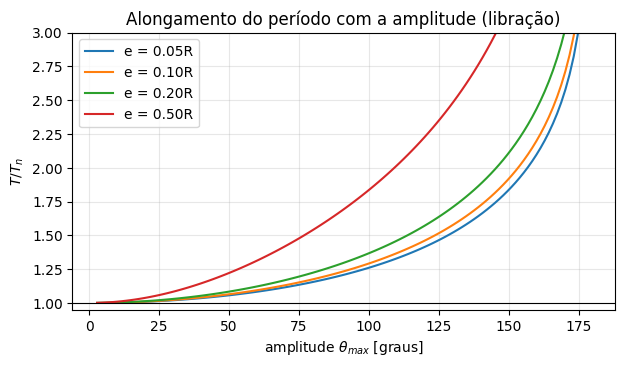

In [14]:
from scipy.integrate import quad

def periodo_exato(theta_max, e, R=0.30, g=9.8):
    Em = g*(R - e*np.cos(theta_max))
    def integrando(u):                      # substituição theta = theta_max * sin(u) remove a singularidade
        th_ = theta_max*np.sin(u)
        om2 = 2*(Em - g*(R - e*np.cos(th_)))/(1.5*R**2 - 2*R*e*np.cos(th_))
        return theta_max*np.cos(u)/np.sqrt(max(om2, 1e-300))
    val, _ = quad(integrando, 0, np.pi/2, limit=200)
    return 4*val

amps = np.linspace(0.05, 0.995*np.pi, 120)
fig, ax = plt.subplots(figsize=(7, 3.6))
for er in [0.05, 0.10, 0.20, 0.50]:
    e_ = er*R_num; Tn = 2*np.pi/np.sqrt(2*g_num*e_/(R_num*(3*R_num - 4*e_)))
    ax.plot(amps*180/np.pi, [periodo_exato(a, e_)/Tn for a in amps], label=f"e = {er:.2f}R")
ax.axhline(1.0, color="k", lw=0.8)
ax.set_xlabel(r"amplitude $\theta_{max}$ [graus]"); ax.set_ylabel(r"$T/T_n$"); ax.set_ylim(0.95, 3)
ax.set_title("Alongamento do período com a amplitude (libração)"); ax.legend(); plt.show()

### (b) Hipóteses de contato e de rolamento sem escorregamento

O modelo pressupõe $N>0$ (sem perda de contato) e $|F|\le\mu N$ (sem escorregamento). Com as expressões de $N$ e $F$ obtidas no item 1.1
podemos verificar, para cada cenário, o coeficiente de atrito mínimo necessário $\mu_{min}=\max_t|F|/N$ e se a normal chega a se anular.
Isso antecipa a motivação da placa imantada usada nas Partes 2 e 3.

velocidade de perda de contato em theta = pi (e = 0,2R): sqrt(g/e) = 12.78 rad/s

 Cenário   N_min/(mg)   mu_min = max|F|/N   contato mantido?
   1.1        0.997           0.045            sim
   1.2        0.991           0.072            sim
   1.3        0.970           0.129            sim
   1.4        0.963           0.120            sim
   1.5        0.960           0.118            sim
   1.6        1.000           0.017            sim
   1.7        0.901           0.248            sim
   1.8        0.992           0.063            sim
   extra       -0.200             inf            NÃO (N<0)


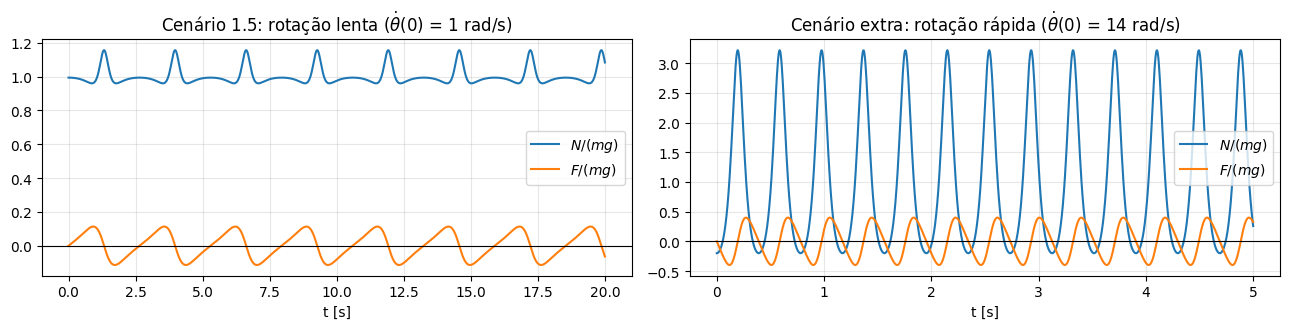

In [15]:
N_f = sp.lambdify((th, thd, thdd, m, R, e, g), N_expr, "numpy")
F_f = sp.lambdify((th, thd, thdd, m, R, e, g), F_expr, "numpy")

# cenário extra: rotação rápida (theta(0) = pi, thetaponto(0) = 14 rad/s) para testar a perda de contato
# (em theta = pi tem-se N = m(g - e*thetaponto^2), que se anula para thetaponto = sqrt(g/e) ~ 12,8 rad/s com e = 0,2R)
resultados["extra"] = simular(np.pi, 14.0, 0.2*R_num, t_final=5.0)
cenarios_chk = dict(cenarios, extra=dict(e=0.20, th0=np.pi, om0=14.0, tf=5.0))
print(f"velocidade de perda de contato em theta = pi (e = 0,2R): sqrt(g/e) = {np.sqrt(g_num/(0.2*R_num)):.2f} rad/s\n")
print(" Cenário   N_min/(mg)   mu_min = max|F|/N   contato mantido?")
for nome, c in cenarios_chk.items():
    e_ = c["e"]*R_num
    t_, th_, om_ = resultados[nome]
    acc = np.array(f_estados(0, [th_, om_], e_, R_num, g_num)[1])
    N_ = N_f(th_, om_, acc, 1.0, R_num, e_, g_num); F_ = F_f(th_, om_, acc, 1.0, R_num, e_, g_num)
    ok = np.all(N_ > 0)
    mu = np.max(np.abs(F_[N_ > 0])/N_[N_ > 0]) if ok else np.inf
    print(f"   {nome}      {np.min(N_)/g_num:7.3f}        {mu:8.3f}            {'sim' if ok else 'NÃO (N<0)'}")

# forças de contato nos cenários 1.5 (rotação lenta) e extra (rotação rápida)
fig, axs = plt.subplots(1, 2, figsize=(13, 3.4))
for ax, nome, titulo in zip(axs, ["1.5", "extra"], [r"Cenário 1.5: rotação lenta ($\dot\theta(0)$ = 1 rad/s)", r"Cenário extra: rotação rápida ($\dot\theta(0)$ = 14 rad/s)"]):
    t_, th_, om_ = resultados[nome]; e_ = 0.2*R_num
    acc = np.array(f_estados(0, [th_, om_], e_, R_num, g_num)[1])
    ax.plot(t_, N_f(th_, om_, acc, 1.0, R_num, e_, g_num)/g_num, label=r"$N/(mg)$")
    ax.plot(t_, F_f(th_, om_, acc, 1.0, R_num, e_, g_num)/g_num, label=r"$F/(mg)$")
    ax.axhline(0, color="k", lw=0.8); ax.set_xlabel("t [s]"); ax.set_title(titulo); ax.legend()
plt.tight_layout(); plt.show()

### (c) Novos cenários: varredura da velocidade inicial em torno da separatriz e variação de $e$

Partindo de $\theta_0=0$, a velocidade que leva exatamente à separatriz é $\dot\theta_{sep}=\sqrt{8ge/(3R^2-4Re)}$.
Valores ligeiramente abaixo e acima mostram a transição libração → rotação, e a dependência do comportamento com a excentricidade $e$.

velocidade da separatriz em theta=0 (e = 0,2R): 4.8742 rad/s


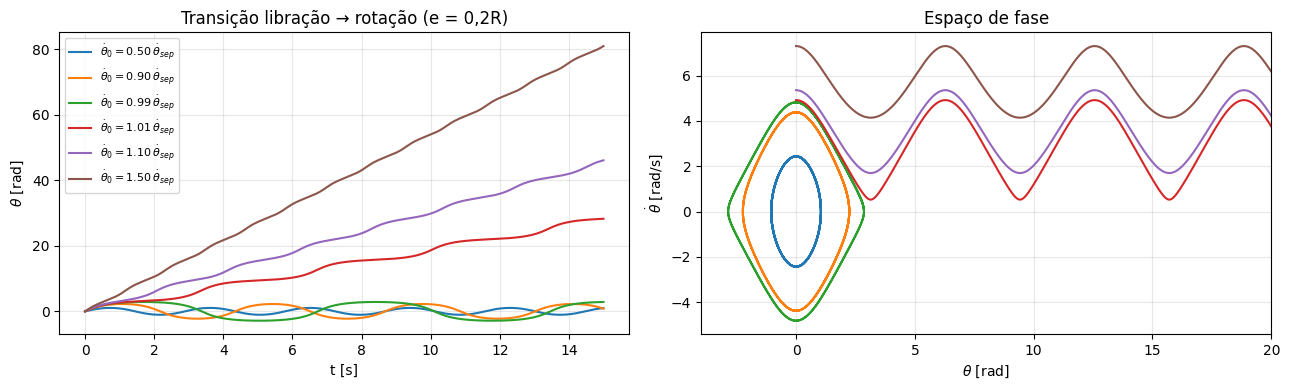

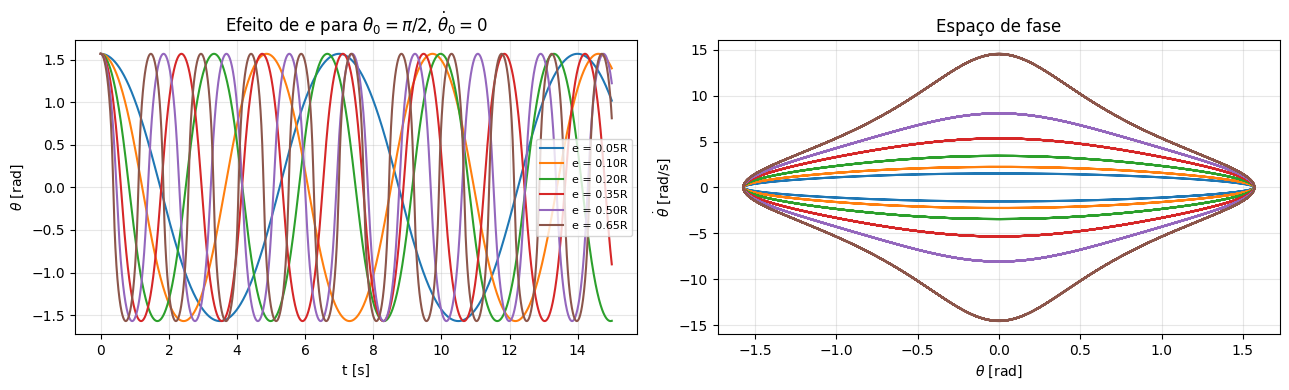

In [16]:
e_ = 0.20*R_num
om_sep = np.sqrt(8*g_num*e_/(3*R_num**2 - 4*R_num*e_))
print(f"velocidade da separatriz em theta=0 (e = 0,2R): {om_sep:.4f} rad/s")

fig, axs = plt.subplots(1, 2, figsize=(13, 4))
for frac in [0.5, 0.9, 0.99, 1.01, 1.1, 1.5]:
    t_, th_, om_ = simular(0.0, frac*om_sep, e_, t_final=15.0)
    axs[0].plot(t_, th_, label=rf"$\dot\theta_0={frac:.2f}\,\dot\theta_{{sep}}$")
    axs[1].plot(th_, om_)
axs[0].set_xlabel("t [s]"); axs[0].set_ylabel(r"$\theta$ [rad]"); axs[0].set_title("Transição libração → rotação (e = 0,2R)"); axs[0].legend(fontsize=8)
axs[1].set_xlabel(r"$\theta$ [rad]"); axs[1].set_ylabel(r"$\dot\theta$ [rad/s]"); axs[1].set_title("Espaço de fase"); axs[1].set_xlim(-4, 20)
plt.tight_layout(); plt.show()

# mesma condição inicial (pi/2, 0) para diferentes excentricidades
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
for er in [0.05, 0.10, 0.20, 0.35, 0.50, 0.65]:
    t_, th_, om_ = simular(np.pi/2, 0.0, er*R_num, t_final=15.0)
    axs[0].plot(t_, th_, label=f"e = {er:.2f}R"); axs[1].plot(th_, om_)
axs[0].set_xlabel("t [s]"); axs[0].set_ylabel(r"$\theta$ [rad]"); axs[0].set_title(r"Efeito de $e$ para $\theta_0=\pi/2$, $\dot\theta_0=0$"); axs[0].legend(fontsize=8)
axs[1].set_xlabel(r"$\theta$ [rad]"); axs[1].set_ylabel(r"$\dot\theta$ [rad/s]"); axs[1].set_title("Espaço de fase")
plt.tight_layout(); plt.show()

**Observações da exploração.**

* O alongamento do período com a amplitude é a assinatura mais visível da não-linearidade; a tolerância da linearização depende de $e$: para $e$ pequeno a inércia $I_C$
  quase não varia e o sistema se comporta como um pêndulo simples; para $e$ grande o termo $Re\dot\theta^2\sin\theta$ e a variação de $I_C$ deformam a forma de onda.
* Em todos os cenários propostos as hipóteses do modelo são consistentes: a normal nunca cai abaixo de $0{,}9\,mg$ e o coeficiente de atrito exigido
  é modesto ($\mu_{min}\le0{,}25$, maior no cenário 1.7, de maior excentricidade). Em $\theta=\pi$ tem-se $N=m(g-e\dot\theta^2)$, de modo que
  rotações rápidas ($\dot\theta>\sqrt{g/e}\approx12{,}8$ rad/s para $e=0{,}2R$) levariam à **perda de contato** (cenário extra, $N<0$) — daí a placa imantada das Partes 2 e 3.
* A velocidade crítica $\dot\theta_{sep}$ separa de forma abrupta dois regimes qualitativamente distintos (curva fechada × aberta), e o período diverge logaritmicamente
  ao se aproximar dela, por ambos os lados.
* Quanto maior $e$, maior $\omega_n$ e menor $\ell_{eq}$: o corpo "mais excêntrico" é um pêndulo mais curto e mais rápido; a dependência $\omega_n(e)$ é a base
  da escolha da rigidez da placa na Parte 3.